# Gaussian Naive Bayes

Assumes each feature is normally distributed within a class and independent given the class. Fits per-class mean/variance, predicts via Bayes' rule using log-probabilities for numerical stability.

## Usage

```python
# (the class is defined in the Implementation section below)

model = GaussianNaiveBayes().fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class GaussianNaiveBayes:
    """Gaussian Naive Bayes: per-class feature mean/variance, assumes feature independence."""

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing
        self.classes = None
        self.mean = None
        self.var = None
        self.priors = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes = np.unique(y)
        n_features = X.shape[1]
        n_classes = len(self.classes)

        self.mean = np.zeros((n_classes, n_features))
        self.var = np.zeros((n_classes, n_features))
        self.priors = np.zeros(n_classes)

        epsilon = self.var_smoothing * X.var(axis=0).max()
        for i, c in enumerate(self.classes):
            X_c = X[y == c]
            self.mean[i] = X_c.mean(axis=0)
            self.var[i] = X_c.var(axis=0) + epsilon
            self.priors[i] = X_c.shape[0] / X.shape[0]
        return self

    def _log_likelihood(self, X):
        # log N(x; mean, var) summed over features, for each class -> (n_samples, n_classes)
        log_probs = []
        for i in range(len(self.classes)):
            log_prior = np.log(self.priors[i])
            diff = X - self.mean[i]
            log_gauss = -0.5 * np.sum(np.log(2 * np.pi * self.var[i])) - 0.5 * np.sum(
                (diff**2) / self.var[i], axis=1
            )
            log_probs.append(log_prior + log_gauss)
        return np.array(log_probs).T

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        log_probs = self._log_likelihood(X)
        return self.classes[np.argmax(log_probs, axis=1)]

## See it work

### 1. One Gaussian per class per feature

Naive Bayes models each feature **independently** within each class with a Gaussian (`mean`, `var`). For one feature (iris petal length) you can see exactly what it learned: three bell curves, and a new point goes to the class whose curve (times its prior) is highest.

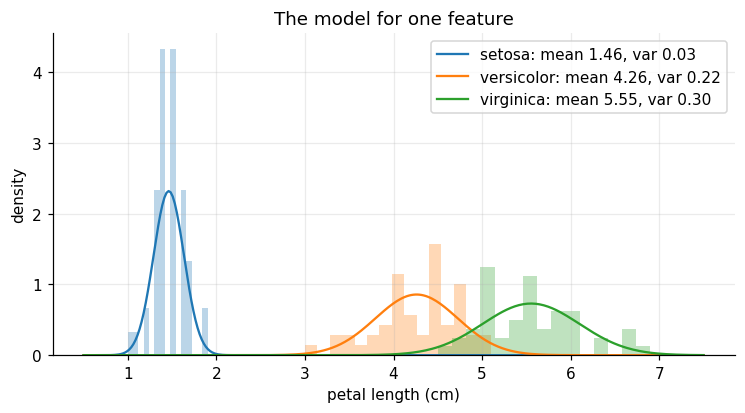

In [3]:
from sklearn.datasets import load_iris

iris = load_iris()
f = 2                                               # petal length
nb = GaussianNaiveBayes().fit(iris.data, iris.target)
xs = np.linspace(0.5, 7.5, 300)
plt.figure(figsize=(8, 3.8))
for c, name in enumerate(iris.target_names):
    mu, var = nb.mean[c, f], nb.var[c, f]
    plt.hist(iris.data[iris.target == c, f], bins=15, density=True, alpha=0.3, color=f"C{c}")
    plt.plot(xs, np.exp(-(xs - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var), color=f"C{c}", label=f"{name}: mean {mu:.2f}, var {var:.2f}")
plt.xlabel("petal length (cm)"); plt.ylabel("density"); plt.legend(); plt.title("The model for one feature"); plt.show()

### 2. Decision regions in 2-D

With two features the boundaries between classes are smooth quadratic curves (each class has its own variance, so the Gaussians have different widths).

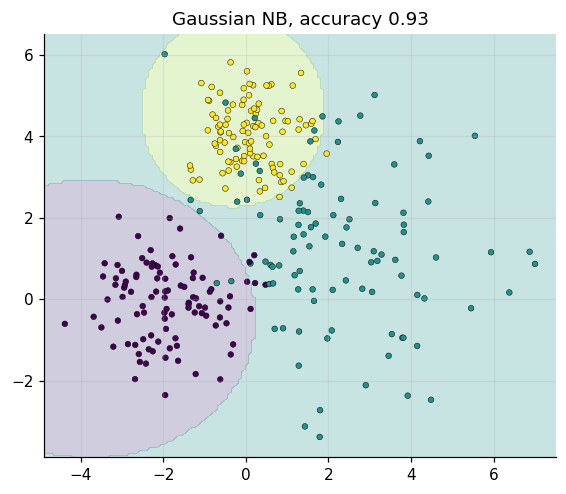

In [4]:
from sklearn.datasets import make_blobs
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

X, y = make_blobs(n_samples=300, centers=[[-2, 0], [2, 1], [0, 4]], cluster_std=[1.0, 1.8, 0.8], random_state=4)
m = GaussianNaiveBayes().fit(X, y)
fig, ax = plt.subplots(figsize=(6, 5)); plot_boundary(ax, m, X, y, cmap="viridis")
ax.set_title(f"Gaussian NB, accuracy {(m.predict(X) == y).mean():.2f}"); plt.show()

### 3. The "naive" assumption in action

The model multiplies per-feature likelihoods as if features were independent given the class. That is wrong when features are correlated, but the *ranking* of classes is often still right, which is why naive Bayes works better than it deserves to. Its probabilities, however, tend to be over-confident.

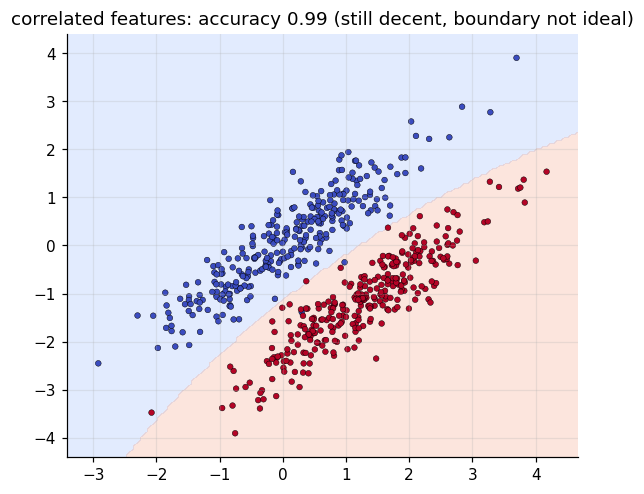

In [5]:
rng = np.random.default_rng(0)
cov = [[1, 0.9], [0.9, 1]]
Xc = np.vstack([rng.multivariate_normal([0, 0], cov, 300), rng.multivariate_normal([1.2, -1.2], cov, 300)])
yc = np.array([0] * 300 + [1] * 300)
m = GaussianNaiveBayes().fit(Xc, yc)
fig, ax = plt.subplots(figsize=(6, 5)); plot_boundary(ax, m, Xc, yc)
ax.set_title(f"correlated features: accuracy {(m.predict(Xc) == yc).mean():.2f} (still decent, boundary not ideal)"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB as SklearnGNB

data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = GaussianNaiveBayes().fit(X_train, y_train)
theirs = SklearnGNB().fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("iris test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert acc_ours == acc_theirs, "Gaussian NB should match sklearn exactly on iris"

iris test accuracy: ours=0.9778 sklearn=0.9778


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_separated_clusters():
    rng = np.random.default_rng(0)
    class0 = rng.normal(loc=-5, scale=0.5, size=(100, 2))
    class1 = rng.normal(loc=5, scale=0.5, size=(100, 2))
    X = np.vstack([class0, class1])
    y = np.array([0] * 100 + [1] * 100)

    model = GaussianNaiveBayes().fit(X, y)
    preds = model.predict(X)
    accuracy = (preds == y).mean()
    assert accuracy > 0.98, accuracy


def test_iris_like_accuracy():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.3, random_state=0
    )
    model = GaussianNaiveBayes().fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracy = (preds == y_test).mean()
    assert accuracy > 0.9, accuracy

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_separated_clusters
PASS test_iris_like_accuracy

all 2 tests passed


## Takeaways

- **Use it** as a very fast baseline, for small datasets, high-dimensional data and as the classic text classifier (`13_multinomial_bernoulli_nb`). Training is one pass computing means and variances.
- **Prediction:** `argmax_c  log P(c) + Σⱼ log N(xⱼ; μ_cj, σ²_cj)`; add `var_smoothing` to the variances so a constant feature does not give zero variance.
- **Pitfalls:** independence assumption (correlated features double count), Gaussian assumption (check feature histograms), probabilities are over-confident.
- **Interview line:** *"Bayes' rule with conditional independence: log prior plus the sum of per-feature log-likelihoods."*